# 08 · Turbulence that changes during a run

A **turbulence schedule** changes the strength of the turbulence while the run is going: a fade, a ramp, a
gust, a different curve per layer. It is a table with one row per tick and one column per layer (README §5.1).

**How it acts.** Each layer's screen moves with the wind by *extrusion*: every tick new rows are added on one
side and the same number drop off the other. Each new row is predicted from the last rows plus fresh randomness,

    new_row = A · (last rows of the screen) + b · B · ξ,      ξ ~ N(0, 1)

and the schedule sets the multiplier **b** on the fresh-randomness term. The phase variance of new rows scales
with b², so the layer's Cn² scales by b², and since r₀ ∝ (Cn²)^(−3/5), a target r₀ needs
**b = (r₀,base / r₀)^(5/6)**. b = 1 is the configured channel; b = 0 freezes the screen.

**What to expect.** Only *new* rows get the new strength; rows already in the screen keep theirs until they
scroll out. After a change, each layer therefore reaches its new strength over about `N / rows_extruded` ticks.

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


In [2]:
config = opal.load_config("configs/quickstart_256.json")
sim = opal.GpuSimulator(config)
info = sim.describe()
N = info["grid"]

print("layer  height (m)  wind (m/s)  rows/tick  ticks to refresh the screen (N / rows)")
for layer in info["layers"]:
    print(f"{layer['layer']:5d} {layer['height_m']:11.0f} {layer['wind_mps']:11.1f} {layer['rows_extruded']:10d}"
          f" {N / layer['rows_extruded']:12.0f}")

layer  height (m)  wind (m/s)  rows/tick  ticks to refresh the screen (N / rows)
    0          95         6.9          2          128
    1         179         8.0          2          128
    2         330        10.0          3           85
    3        1416        24.7          5           51
    4        3785        60.3         13           20
    5        7942       132.4         27            9
    6       10063       161.2         33            8
    7       11888       177.7         36            7
    8       14096       194.1         39            7
    9       20065       258.0         52            5


## 1. A ramp: r₀ from 10 cm down to 5 cm

The path r₀ is held at 10 cm for 100 ticks, ramps down to 5 cm over the next 200 ticks, and stays there. With
`kind="path_r0"` the numbers are the total-path r₀ in metres, one per tick, and every layer gets the same b.
`build_schedule` shows the b values the graph will actually use.

b schedule: (600, 10) | first 0.99999845 | last 1.782 | expected (0.10/0.05)^(5/6) = 1.782


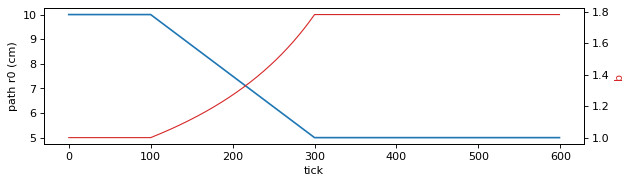

In [3]:
T = 600
path_r0 = np.interp(np.arange(T), [0, 100, 300, T - 1], [0.10, 0.10, 0.05, 0.05]).astype(np.float32)
b = opal.build_schedule(path_r0, T, sim.num_layers, base_r0=np.asarray(sim.get_state()["base_r0"]), kind="path_r0")
print("b schedule:", b.shape, "| first", b[0, 0], "| last", round(float(b[-1, 0]), 3),
      "| expected (0.10/0.05)^(5/6) =", round(2 ** (5 / 6), 3))

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot(path_r0 * 100, label="target path r0 (cm)")
ax2 = ax.twinx()
ax2.plot(b[:, 0], color="tab:red", lw=1, label="b")
ax.set(xlabel="tick", ylabel="path r0 (cm)")
ax2.set_ylabel("b", color="tab:red")
plt.tight_layout()
plt.show()

## 2. Run it, next to a constant run

Both runs use the same seed, so they start from identical screens; any difference comes from the schedule.
The schedule is saved in the run directory (`schedule.npy`), and `analyze_run` uses it to attach the target r₀
to every frame.

In [4]:
const = opal.run(sim, T, out_dir="runs/schedules/constant", log=None)
ramp = opal.run(sim, T, schedule=path_r0, schedule_kind="path_r0", out_dir="runs/schedules/ramp")
print("\nfiles:", sorted(p.name for p in Path("runs/schedules/ramp").iterdir()))

[opal    0.24s] memory plan: N=256 steps=600 requested=auto -> device


[opal    0.24s]   frame 0.5 MiB | output 0.29 GiB | baseline 0.04 GiB | margin 3.20 GiB | GPU 15.99 GiB | RAM avail 33.59 GiB


[opal    0.24s]   predicted GPU peak: device 3.82 GiB | host 3.24 GiB | chunked 3.34 GiB (chunk<=100)


[opal    0.24s] guard: auto: full output fits on the GPU -> device


[opal    0.25s] running device mode: 600 steps, N=256, 10 layers


[opal  130.01s] device: 600 steps in 129.76 s (216.27 ms/step)


[opal  130.31s] wrote frames.npy (0.29 GiB) in 0.3 s


[opal  130.34s] done: 600 steps simulated in 129.76 s | 4.6 steps/s | peak GPU 0.62 GiB | writing frames 0.3 s


[opal  130.37s] wrote runs\schedules\ramp\manifest.json



files: ['frames.npy', 'manifest.json', 'schedule.npy']


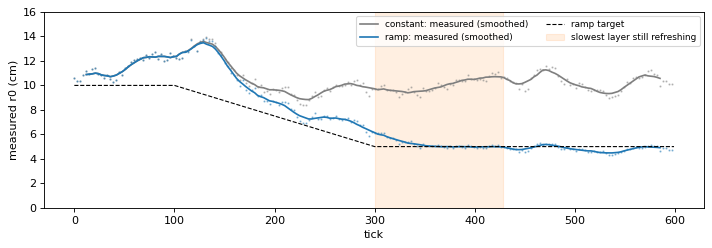

after the slowest layer has refreshed: measured r0 median 0.048 m (target 0.050 m)


In [5]:
for name in ("constant", "ramp"):
    opal.analyze_run(f"runs/schedules/{name}", "r0", frames="all", stride=3, log=None)

def smooth(x, k=9):
    return np.convolve(x, np.ones(k) / k, mode="valid"), k // 2

slowest = max(N / layer["rows_extruded"] for layer in info["layers"])
fig, ax = plt.subplots(figsize=(9, 3.2))
for name, color in (("constant", "tab:gray"), ("ramp", "tab:blue")):
    steps, values, extra = opal.load_analysis(f"runs/schedules/{name}", "r0")
    ax.plot(steps, values * 100, ".", ms=2, color=color, alpha=0.4)
    sm, h = smooth(values)
    ax.plot(steps[h:len(steps) - h], sm * 100, color=color, label=f"{name}: measured (smoothed)")
ax.plot(path_r0 * 100, "k--", lw=1, label="ramp target")
ax.axvspan(300, min(T, 300 + slowest), color="tab:orange", alpha=0.12, label="slowest layer still refreshing")
ax.set(xlabel="tick", ylabel="measured r0 (cm)", ylim=(0, 16))
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

steps, values, extra = opal.load_analysis("runs/schedules/ramp", "r0")
late = steps >= 300 + slowest
print(f"after the slowest layer has refreshed: measured r0 median {np.median(values[late]):.3f} m "
      f"(target {extra['target_r0_m'][late][0]:.3f} m)")

The measured r₀ follows the target with a lag: the fast high layers pick up the new strength within a few
ticks, the slow ground layer only once its screen has scrolled through. Changes that are slow compared with
the refresh times are reproduced accurately; for large, sudden changes with exact statistics use `opal pass`
(notebook 04), which rebuilds the operators instead.

## 3. The four kinds describe the same thing

The same ramp written as a b multiplier, a Cn² multiplier, per-layer r₀ or path r₀ gives the same b schedule:

In [6]:
base = np.asarray(sim.get_state()["base_r0"])
b_ramp = (0.10 / path_r0) ** (5 / 6)
forms = {
    "b_scale": b_ramp,
    "cn2": b_ramp ** 2,
    "r0": base[None, :] * (path_r0 / 0.10)[:, None],
    "path_r0": path_r0,
}
built = {kind: opal.build_schedule(v, T, sim.num_layers, base_r0=base, kind=kind) for kind, v in forms.items()}
for kind, bb in built.items():
    print(f"{kind:8s} -> b {bb.shape}, max |b - b(path_r0)| = {np.abs(bb - built['path_r0']).max():.1e}")

b_scale  -> b (600, 10), max |b - b(path_r0)| = 2.7e-06
cn2      -> b (600, 10), max |b - b(path_r0)| = 2.7e-06
r0       -> b (600, 10), max |b - b(path_r0)| = 2.9e-06
path_r0  -> b (600, 10), max |b - b(path_r0)| = 0.0e+00


## 4. From a file on the command line

`opal run --schedule FILE --schedule-kind KIND` accepts `.npy`, `.npz`, `.csv` or `.json`. The CLI run below
reproduces the Python run exactly.

In [7]:
np.savetxt("runs/schedules/ramp.csv", path_r0)
!opal run -c configs/quickstart_256.json --steps 600 --schedule runs/schedules/ramp.csv --schedule-kind path_r0 -o runs/schedules/cli -q

print("CLI run == Python run:", np.array_equal(opal.load_frames("runs/schedules/cli"), opal.load_frames("runs/schedules/ramp")))

{"mode": "device", "steps": 600, "run_time_s": 129.354, "total_s": 147.113, "out_dir": "runs\\schedules\\cli"}


CLI run == Python run: True
